# Study 17 — Weather-conditioned transition: coefficient sensitivity

**Reviewer ask (detailed reviewer, Sec 2.3).** The weather-conditioned transition coefficients (0.9 and 0.7 in
the clipping functions, Sec 2.3.3) are not sensitivity-tested and do not appear in Figure 2. Since the mechanism
is used in the fusion analysis (Sec 3.3), characterise its sensitivity, or drop it if the result is not robust.

**Mechanism (verbatim from study3b).** With stagnation index `st = mean(-z_wind, -z_blh)`:

```
up  = min(max(0.25*(1 + c_up*st), 0.05), 0.6)
pdn = min(max(pdn *(1 - c_dn*st), 0.0 ), 0.4)
```

Paper uses c_up=0.9, c_dn=0.7. This notebook sweeps each coefficient one-at-a-time (holding the other at its
paper value) and reports: (A) complete-data discrimination of the weather-conditioned twin, and (B) the
cross-modal resilience advantage over the PM-only twin under PM-sensor dropout, which is the Sec 3.3 claim.

At c_up=c_dn=0 the mechanism is inert and the weather-conditioned twin collapses to the PM-only twin, so the
advantage there should be ~0 (internal check). cwd=`notebooks/`. Outputs -> `../outputs/study17_weathercoef/`.


## Load + parameterised twin + per-station store (from study3b)


In [1]:
import numpy as np, pandas as pd, math, matplotlib.pyplot as plt
from pathlib import Path
np.random.seed(0)
OUT=Path("../outputs/study17_weathercoef"); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":130,"savefig.dpi":200,"font.size":11,"axes.grid":True,"grid.alpha":0.25,
                     "axes.spines.top":False,"axes.spines.right":False})
STEP=6; H=4; TAU=15.0
pm=pd.read_csv("../data/openaq_regional/regional_pm25.csv"); pm["datetime"]=pd.to_datetime(pm["datetime"],utc=True)
pm["name"]=pm.station.str.split("::").str[1]; pm["city"]=pm.station.str.split("::").str[0]
pm=pm.dropna(subset=["value"]); pm=pm[(pm.value>=0)&(pm.value<1500)]
met=pd.read_csv("../data/era5/era5_regional.csv",usecols=["datetime","station","wind_speed","blh","t2m"])
met["datetime"]=pd.to_datetime(met["datetime"],utc=True); met=met.rename(columns={"station":"name"})
yrs=pm.groupby("station")["datetime"].agg(lambda s:(s.max()-s.min()).days/365.25); pm=pm[pm.station.isin(yrs[yrs>=2].index)].copy()

K=5; _LEVL=[i/(K-1) for i in range(K)]; _SDL=[1.0+0.5*l for l in _LEVL]; _LOGC=0.5*math.log(2*math.pi); _LGCONST=[-_LOGC-math.log(sd) for sd in _SDL]
def _lgv(z): return [_LGCONST[k]-0.5*((z-2.0*_LEVL[k])/_SDL[k])**2 for k in range(K)]
def twin(zpm, stag=None, mm_dyn=False, cup=0.9, cdn=0.7):
    """Parameterised weather-conditioned transition (c_up, c_dn). Paper defaults 0.9, 0.7."""
    logb=[-3*k for k in range(K)]; m=max(logb); ssum=sum(math.exp(x-m) for x in logb); logb=[x-m-math.log(ssum) for x in logb]
    risk=[0.0]*len(zpm)
    for t in range(len(zpm)):
        mb=max(logb); b=[math.exp(x-mb) for x in logb]; sb=sum(b); b=[x/sb for x in b]
        el=sum(b[k]*_LEVL[k] for k in range(K)); up=0.25; pdn=0.05 if el>0.4 else 0.15
        st=None if stag is None else stag[t]
        if mm_dyn and st is not None and not math.isnan(st):
            up=min(max(0.25*(1+cup*st),0.05),0.6); pdn=min(max(pdn*(1-cdn*st),0.0),0.4)
        bp=[0.0]*K
        for k in range(K):
            u=up if k<K-1 else 0.0; d=pdn if k>0 else 0.0; bp[k]+=b[k]*(1-u-d)
            if k<K-1: bp[k+1]+=b[k]*u
            if k>0:   bp[k-1]+=b[k]*d
        logbp=[math.log(x+1e-12) for x in bp]
        z=zpm[t]
        if not math.isnan(z):
            lv=_lgv(z); logbp=[logbp[k]+lv[k] for k in range(K)]
        m2=max(logbp); ss=math.log(sum(math.exp(x-m2) for x in logbp)); logb=[x-m2-ss for x in logbp]
        eb=[math.exp(x) for x in logb]; risk[t]=sum(eb[k]*_LEVL[k] for k in range(K))
    return np.array(risk)
def auc(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);pos,neg=(y==1),(y==0)
    if pos.sum()==0 or neg.sum()==0:return np.nan
    o=np.argsort(s);r=np.empty(len(s));r[o]=np.arange(1,len(s)+1)
    u,inv,c=np.unique(s,return_inverse=True,return_counts=True);ss=np.zeros(len(c));np.add.at(ss,inv,r);r=(ss/c)[inv]
    return float((r[pos].sum()-pos.sum()*(pos.sum()+1)/2)/(pos.sum()*neg.sum()))
def apr(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);o=np.argsort(-s);y=y[o];tp=np.cumsum(y);fp=np.cumsum(1-y);prec=tp/(tp+fp);rec=tp/max(y.sum(),1)
    return float(np.sum((rec-np.r_[0,rec[:-1]])*prec))

# per-station store + test onset points (independent of coefficients)
ST={}
for st,g in pm.groupby("station"):
    name=g["name"].iloc[0]
    s=g.set_index("datetime").value.resample(f"{STEP}h").mean()
    mg=met[met.name==name].set_index("datetime")[["wind_speed","blh","t2m"]].resample(f"{STEP}h").mean()
    idx=s.index; A=pd.DataFrame({"pm":s}).join(mg).reindex(idx); tm=(idx.month%2==0)
    def z(col,log=False):
        v=np.log1p(np.clip(A[col].to_numpy(),0,None)) if log else A[col].to_numpy()
        mu,sd=np.nanmean(v[tm]),np.nanstd(v[tm])+1e-9; return (v-mu)/sd
    zpm=z("pm",log=True); zw=z("wind_speed"); zb=z("blh")
    stag=np.nanmean(np.vstack([-zw,-zb]),axis=0); v=A["pm"].to_numpy()
    tpts=[]
    for t in range(2,len(v)-H):
        if np.isnan(v[t]) or v[t]>=TAU or tm[t]: continue
        fut=v[t+1:t+1+H]
        if np.all(np.isnan(fut)): continue
        tpts.append((t,int(np.nanmax(fut)>=TAU)))
    ST[st]=dict(zpm=zpm,stag=stag,v=v,tm=tm,tpts=tpts)
print("stations",len(ST),"| test onset points",sum(len(d["tpts"]) for d in ST.values()))


/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


stations 21 | test onset points 48209


## A. Complete-data discrimination vs coefficients (one-at-a-time)


In [2]:
def complete_auc(cup,cdn):
    sc=[];yy=[]
    for st,d in ST.items():
        r=twin(d["zpm"],stag=d["stag"],mm_dyn=True,cup=cup,cdn=cdn)
        for t,lab in d["tpts"]: sc.append(r[t]); yy.append(lab)
    return auc(sc,yy),apr(sc,yy)

# PM-only reference (mechanism off)
pm_sc=[];pm_y=[]
for st,d in ST.items():
    r=twin(d["zpm"])
    for t,lab in d["tpts"]: pm_sc.append(r[t]); pm_y.append(lab)
AUC_PM,APR_PM=auc(pm_sc,pm_y),apr(pm_sc,pm_y)
print(f"PM-only twin: AUROC {AUC_PM:.4f}  AUPRC {APR_PM:.4f}")

CUP=[0.0,0.45,0.9,1.35,1.8]; CDN=[0.0,0.35,0.7,1.05]
rows=[]
_a,_p=complete_auc(0.0,0.0); rows.append(dict(sweep="off",c_up=0.0,c_dn=0.0,AUROC=_a,AUPRC=_p))  # inert check
for cu in CUP:
    a,p=complete_auc(cu,0.7); rows.append(dict(sweep="c_up",c_up=cu,c_dn=0.7,AUROC=a,AUPRC=p))
for cd in CDN:
    a,p=complete_auc(0.9,cd); rows.append(dict(sweep="c_dn",c_up=0.9,c_dn=cd,AUROC=a,AUPRC=p))
compA=pd.DataFrame(rows); compA["AUROC_vs_PMonly"]=compA.AUROC-AUC_PM
compA.to_csv(OUT/"s17_complete_data.csv",index=False)
print(compA.round(4).to_string(index=False))
print("\nNote: paper reports meteorology does NOT help on complete data; expect AUROC_vs_PMonly <= 0 throughout.")



PM-only twin: AUROC 0.7778  AUPRC 0.1971
sweep  c_up  c_dn  AUROC  AUPRC  AUROC_vs_PMonly
  off  0.00  0.00 0.7778 0.1971           0.0000
 c_up  0.00  0.70 0.7806 0.2103           0.0028
 c_up  0.45  0.70 0.7662 0.2160          -0.0116
 c_up  0.90  0.70 0.7564 0.2125          -0.0214
 c_up  1.35  0.70 0.7502 0.2102          -0.0276
 c_up  1.80  0.70 0.7488 0.2114          -0.0290
 c_dn  0.90  0.00 0.7663 0.2136          -0.0115
 c_dn  0.90  0.35 0.7613 0.2154          -0.0165
 c_dn  0.90  0.70 0.7564 0.2125          -0.0214
 c_dn  0.90  1.05 0.7537 0.2122          -0.0241

Note: paper reports meteorology does NOT help on complete data; expect AUROC_vs_PMonly <= 0 throughout.


## B. Cross-modal resilience advantage vs coefficients (Sec 3.3 claim)


In [3]:
def eval_dropout(cup,cdn,p,seed):
    rng=np.random.default_rng(seed); a_pm=[];a_dyn=[];yy=[]
    for st,d in ST.items():
        zpm=d["zpm"].copy()
        if p>0: zpm[rng.random(len(zpm))<p]=np.nan
        r_pm=twin(zpm); r_dyn=twin(zpm,stag=d["stag"],mm_dyn=True,cup=cup,cdn=cdn)
        for t,lab in d["tpts"]:
            yy.append(lab); a_pm.append(r_pm[t]); a_dyn.append(r_dyn[t])
    return auc(a_pm,yy),auc(a_dyn,yy)

PS=[0.0,0.4,0.7,0.85]
def resilience_row(cup,cdn):
    out={}
    for p in PS:
        seeds=[0] if p==0 else [0,1]
        r=np.mean([eval_dropout(cup,cdn,p,s) for s in seeds],axis=0)
        out[p]=(r[0],r[1],r[1]-r[0])   # pm, dyn, advantage
    return out

rows=[]
settings=[("off",0.0,0.0)]+[("c_up",cu,0.7) for cu in CUP]+[("c_dn",0.9,cd) for cd in CDN]
for sweep,cu,cd in settings:
    res=resilience_row(cu,cd)
    for p in PS:
        pm_a,dyn_a,adv=res[p]
        rows.append(dict(sweep=sweep,c_up=cu,c_dn=cd,dropout=p,auc_pm=pm_a,auc_dyn=dyn_a,advantage=adv))
    print(f"[{sweep}] c_up={cu} c_dn={cd} | adv@85% {res[0.85][2]:+.4f}  adv@70% {res[0.7][2]:+.4f}")
compB=pd.DataFrame(rows); compB.to_csv(OUT/"s17_resilience.csv",index=False)
print("\nsaved resilience CSV")



[off] c_up=0.0 c_dn=0.0 | adv@85% +0.0000  adv@70% +0.0000
[c_up] c_up=0.0 c_dn=0.7 | adv@85% +0.0377  adv@70% +0.0125
[c_up] c_up=0.45 c_dn=0.7 | adv@85% +0.0411  adv@70% +0.0101
[c_up] c_up=0.9 c_dn=0.7 | adv@85% +0.0417  adv@70% +0.0035
[c_up] c_up=1.35 c_dn=0.7 | adv@85% +0.0424  adv@70% +0.0004
[c_up] c_up=1.8 c_dn=0.7 | adv@85% +0.0440  adv@70% +0.0003
[c_dn] c_up=0.9 c_dn=0.0 | adv@85% +0.0441  adv@70% +0.0102
[c_dn] c_up=0.9 c_dn=0.35 | adv@85% +0.0437  adv@70% +0.0071
[c_dn] c_up=0.9 c_dn=0.7 | adv@85% +0.0417  adv@70% +0.0035
[c_dn] c_up=0.9 c_dn=1.05 | adv@85% +0.0414  adv@70% +0.0018

saved resilience CSV


## Figure: one-at-a-time sensitivity


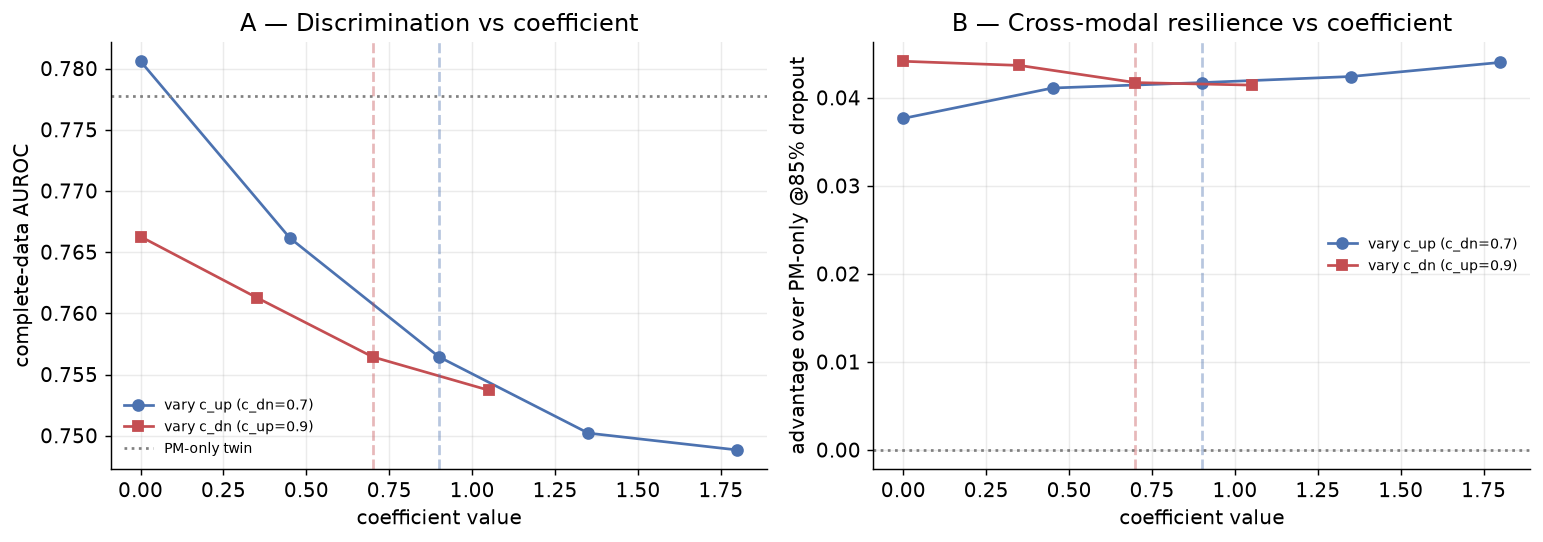

saved figure to ../outputs/study17_weathercoef


In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,4.3))
# A: complete-data AUROC vs each coefficient
up=compA[compA.sweep=="c_up"]; dn=compA[compA.sweep=="c_dn"]
ax[0].plot(up.c_up,up.AUROC,"-o",color="#4C72B0",label="vary c_up (c_dn=0.7)")
ax[0].plot(dn.c_dn,dn.AUROC,"-s",color="#C44E52",label="vary c_dn (c_up=0.9)")
ax[0].axhline(AUC_PM,ls=":",c="grey",label="PM-only twin")
ax[0].axvline(0.9,ls="--",c="#4C72B0",alpha=.4); ax[0].axvline(0.7,ls="--",c="#C44E52",alpha=.4)
ax[0].set_xlabel("coefficient value"); ax[0].set_ylabel("complete-data AUROC")
ax[0].set_title("A — Discrimination vs coefficient"); ax[0].legend(frameon=False,fontsize=8)
# B: 85%-dropout resilience advantage vs each coefficient
b=compB[compB.dropout==0.85]
bu=b[b.sweep=="c_up"]; bd=b[b.sweep=="c_dn"]
ax[1].plot(bu.c_up,bu.advantage,"-o",color="#4C72B0",label="vary c_up (c_dn=0.7)")
ax[1].plot(bd.c_dn,bd.advantage,"-s",color="#C44E52",label="vary c_dn (c_up=0.9)")
ax[1].axhline(0,ls=":",c="grey"); ax[1].axvline(0.9,ls="--",c="#4C72B0",alpha=.4); ax[1].axvline(0.7,ls="--",c="#C44E52",alpha=.4)
ax[1].set_xlabel("coefficient value"); ax[1].set_ylabel("advantage over PM-only @85% dropout")
ax[1].set_title("B — Cross-modal resilience vs coefficient"); ax[1].legend(frameon=False,fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"s17_fig1_weathercoef_sensitivity.png",bbox_inches="tight"); plt.show()
print("saved figure to",OUT)


## Reading this for the reply

- **If the resilience advantage (panel B) stays positive and roughly flat across a wide coefficient range**, the
  mechanism is robust: keep it and cite this sensitivity figure, noting the 0.9/0.7 choice is not load-bearing.
- **If the advantage is near zero, sign-flips, or depends sharply on the exact values**, take the reviewer's
  offered alternative and drop the weather-conditioned transition, keeping only the additive met-observation
  fusion. The paper's conclusions do not depend on this mechanism.
- Panel A should confirm the honest finding that meteorology does not raise complete-data discrimination at any
  coefficient (AUROC_vs_PMonly <= 0), so the mechanism is justified by resilience, not by discrimination.
- Internal check: at c_up=c_dn=0 the advantage must be ~0 (mechanism inert).
